# EN3160 – Assignment 2: Fitting and Alignment

**Name:** Ransara Maldeniya  |  **Index No:** 230390A  |  **GitHub:** https://github.com/ransara3/EN3160-Assignment-2-Fitting-and-Alignment.git



## Setup

I used NumPy, OpenCV, Matplotlib and SciPy for these tasks. The sunflower photograph is stored in the `images` folder. For Q2, I generated the line and circle points in the notebook and used fixed random seeds to keep the results reproducible.


In [1]:
from pathlib import Path
import sys
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import minimize

plt.rcParams["figure.dpi"] = 110
# Locate the image folder.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "images").is_dir():
    matches = list(PROJECT_DIR.glob("*/EN3160_Assignment2.ipynb"))
    if len(matches) == 1:
        PROJECT_DIR = matches[0].parent
IMAGE_DIR = PROJECT_DIR / "images"
print("Python:", sys.executable)
print("Image directory:", IMAGE_DIR.resolve())
def show(img_bgr, title="", figsize=(9, 6)):
    plt.figure(figsize=figsize); plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

Python: C:\Users\ASUS\Desktop\CV\EN3160-Assignment-2-Fitting-and-Alignment\.venv\Scripts\python.exe
Image directory: C:\Users\ASUS\Desktop\CV\EN3160-Assignment-2-Fitting-and-Alignment\images


---
# Q1 – Blob detection with LoG and scale-space extrema

I used the scale-normalised Laplacian of Gaussian to detect blobs in the sunflower image. For an ideal bright circular disk of radius $r$, the response is strongest at $\sigma=r/\sqrt{2}$. Multiplying the LoG response by $\sigma^2$ allows responses at different scales to be compared.

I converted the image to grayscale and calculated $-\sigma^2\nabla^2(G_\sigma*I)$ at geometrically spaced scales, $\sigma_i=\sigma_0k^i$. I used the negative sign to detect bright regions. I then selected local maxima across position and scale using a $3\times3\times3$ neighbourhood, applied a response threshold, and removed nearby weaker detections. For each remaining blob, I estimated the radius as $r=\sqrt{2}\sigma$.


In [2]:
# Parameters
IMG_PATH   = IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg"
SIGMA_MIN  = 3.0      # Minimum scale
SIGMA_MAX  = 40.0     # Maximum scale
N_SCALES   = 20       # Geometrically spaced scales
THRESH     = 0.05     # Response threshold for intensities in [0, 1]
BRIGHT     = True     # Bright blob detection


if not IMG_PATH.is_file():
    raise FileNotFoundError(f"Image not found: {IMG_PATH.resolve()}. Open the notebook from the project folder.")
im = cv.imread(str(IMG_PATH), cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise ValueError(f"OpenCV could not decode {IMG_PATH}")
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
print("image size (H,W):", gray.shape)

sigmas = np.geomspace(SIGMA_MIN, SIGMA_MAX, N_SCALES)

def log_scale_space(gray, sigmas, bright=True):
    stack = np.empty((len(sigmas),) + gray.shape, np.float32)
    sign = -1.0 if bright else 1.0
    for i, s in enumerate(sigmas):
        g = cv.GaussianBlur(gray, (0, 0), s)
        stack[i] = sign * (s ** 2) * cv.Laplacian(g, cv.CV_32F, ksize=1)
    return stack

def detect_blobs(stack, sigmas, thresh, overlap_factor=1.0):
    mx = ndi.maximum_filter(stack, size=(3, 3, 3), mode="nearest")
    peaks = (stack == mx) & (stack > thresh)
    peaks[0] = False; peaks[-1] = False          # Exclude the boundary scales.
    idx = np.argwhere(peaks)                      # (scale, y, x)
    resp = stack[peaks]
    order = np.argsort(-resp)
    blobs = [(x, y, sigmas[s], np.sqrt(2) * sigmas[s], r)
             for (s, y, x), r in zip(idx[order], resp[order])]
    # Keep stronger detections when centres are close.
    kept = []
    for b in blobs:
        if all(np.hypot(b[0] - k[0], b[1] - k[1]) > overlap_factor * max(b[3], k[3]) for k in kept):
            kept.append(b)
    return kept

stack = log_scale_space(gray, sigmas, BRIGHT)
blobs = detect_blobs(stack, sigmas, THRESH)
H, W = gray.shape
margin = 0.5   # Minimum border distance as a fraction of the radius
blobs = [b for b in blobs
         if b[0] - margin*b[3] >= 0 and b[1] - margin*b[3] >= 0
         and b[0] + margin*b[3] < W and b[1] + margin*b[3] < H]
print(f"sigma range used: [{sigmas[0]:.2f}, {sigmas[-1]:.2f}]  ({N_SCALES} scales, k = {sigmas[1]/sigmas[0]:.3f})")
print("blobs detected:", len(blobs))

image size (H,W): (360, 360)
sigma range used: [3.00, 40.00]  (20 scales, k = 1.146)
blobs detected: 96


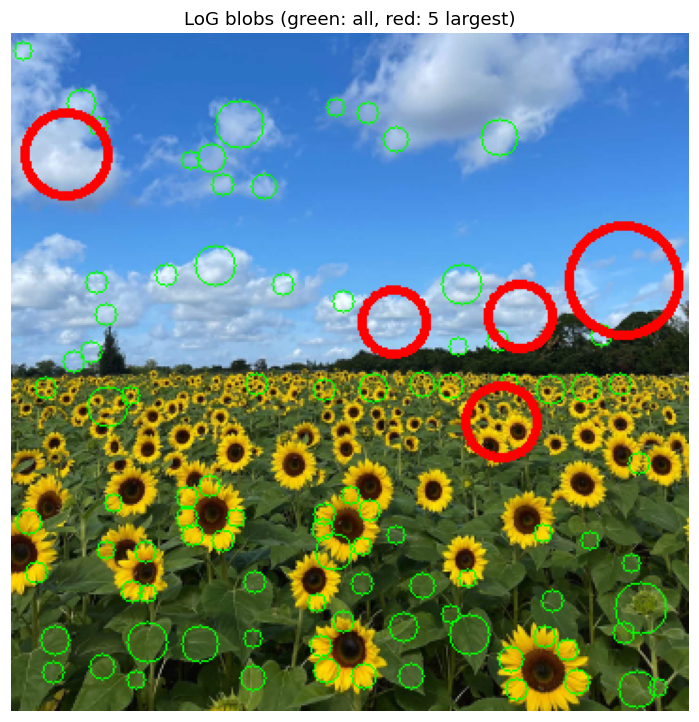

Largest circles:
 #      x      y   sigma   radius=sqrt2*sigma  response
 1    325    131   20.23                28.61     0.136
 2     29     64   15.40                21.78     0.144
 3    260    206   13.44                19.01     0.109
 4    270    150   11.73                16.58     0.181
 5    203    153   11.73                16.58     0.134


In [3]:
# Mark all detections in green and the five largest in red.
largest = sorted(blobs, key=lambda b: -b[3])[:5]
out = im.copy()
for x, y, s, r, _ in blobs:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 255, 0), 1)
for x, y, s, r, _ in largest:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 0, 255), 3)
show(out, "LoG blobs (green: all, red: 5 largest)", (11, 8))

print("Largest circles:")
print(f"{'#':>2} {'x':>6} {'y':>6} {'sigma':>7} {'radius=sqrt2*sigma':>20} {'response':>9}")
for i, (x, y, s, r, resp) in enumerate(largest, 1):
    print(f"{i:>2} {x:>6.0f} {y:>6.0f} {s:>7.2f} {r:>20.2f} {resp:>9.3f}")


### Q1 – Discussion

I used a quarter-size version of the photograph, giving an image of 360 × 360 pixels. I selected 20 scales between σ = 3 and 40, with a scale ratio of approximately 1.146. This corresponds to nominal radii of 4.24–56.57 pixels. With a response threshold of 0.05, the method retained 96 blobs after suppression and border filtering.

The five largest detections were:

| # | x | y | σ | Radius (px) | Response |
|---|---|---|---|---|---|
| 1 | 325 | 131 | 20.23 | 28.61 | 0.136 |
| 2 | 29 | 64 | 15.40 | 21.78 | 0.144 |
| 3 | 260 | 206 | 13.44 | 19.01 | 0.109 |
| 4 | 270 | 150 | 11.73 | 16.58 | 0.181 |
| 5 | 203 | 153 | 11.73 | 16.58 | 0.134 |

These coordinates and radii refer to the reduced image. The radii in the original photograph are approximately four times larger. The largest detection had a radius of 28.61 pixels at (325, 131), and its scale was within the selected range. However, this alone does not show that the range covers every flower size. The first and last scales were excluded because they do not have neighbouring scales on both sides.

From the output image, I noticed that some large circles were drawn over clouds. The detection at (325, 131) is one example. LoG responds to bright, roughly circular regions, so these detections cannot all be counted as sunflower heads. The flowers also have dark centres surrounded by bright petals, which differs from the ideal bright disk used in the radius calculation. Small flowers in the distance can be missed at the selected scales.

The response strength did not increase directly with radius. For example, detection 4 had a response of 0.181, while the largest detection had a response of 0.136. This is because the response depends on contrast as well as size. I therefore sorted the detections by radius when selecting the five largest circles.

A higher threshold would remove more weak detections but could also miss low-contrast flowers. A lower threshold would include more texture and background regions. The geometric spacing gives a radius change of about 14.6% between scales. The distance-based suppression reduces repeated detections, although it can also remove nearby flowers and does not eliminate every overlap.

For the border filter, I required each centre to be at least half its radius from the image edge. This reduces detections near the boundary, but it is not a measurement of how much circle area lies outside the image. Since this filter runs after suppression, a border detection may already have removed another candidate. Overall, cloud responses, overlapping flowers, perspective and irregular flower shapes limit the accuracy. Colour information or a mask for the flower region could help reduce the background detections.


---
# Q2 – RANSAC line and circle fitting

I generated 100 points using the setup in Listing 1. Fifty points came from a circle with centre (2, 3), radius 10 and radial noise with standard deviation 0.625. The other 50 came from the line y = −x + 2, with vertical noise of standard deviation 1.


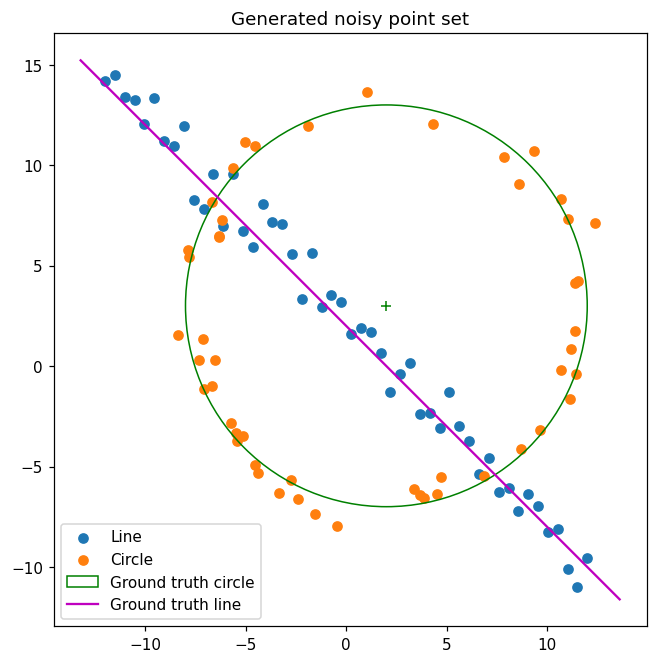

In [4]:
np.random.seed(0)           # Fixed seed for the generated points
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.0
m_gt, b_gt = -1, 2
x = np.linspace(-12, 12, half_n)
y = m_gt * x + b_gt + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color="g", fill=False, label="Ground truth circle"))
ax.plot(x0_gt, y0_gt, "+", color="g")
x_ = np.array(ax.get_xlim()); ax.plot(x_, m_gt * x_ + b_gt, color="m", label="Ground truth line")
ax.set_aspect("equal"); ax.legend(); ax.set_title("Generated noisy point set"); plt.show()

## Q2(a) – RANSAC line fitting

I represented the line as $ax+by=d$, with $\sqrt{a^2+b^2}=1$. For each two-point sample, I calculated a unit normal perpendicular to the direction between the points. This makes the residual $|ax_i+by_i-d|$ the perpendicular distance to the line.

I selected the model with the most inliers, using mean inlier error to break ties. I refined its consensus using total least squares: after subtracting the centroid, I used the right singular vector corresponding to the smallest singular value as the normal.

I used a distance threshold of 1.5 and required at least 35 inliers. The vertical noise has standard deviation 1, so its perpendicular standard deviation for this line is $1/\sqrt{2}$. The threshold is therefore about 2.12 perpendicular standard deviations, covering roughly 97% of true line points under the noise model.

For confidence $p=0.999$, assumed inlier fraction $w=0.4$ and sample size $s=2$, the iteration estimate

$$N=\frac{\log(1-p)}{\log(1-w^s)}$$

gives 40 trials. I used 200 trials to allow more sampling opportunities.


In [5]:
def n_iters(p, w, s):
    return int(np.ceil(np.log(1 - p) / np.log(1 - w ** s)))

# Line model
def line_from_2pts(p1, p2):
    dx, dy = p2 - p1
    nrm = np.array([-dy, dx]); L = np.linalg.norm(nrm)
    if L < 1e-9: return None
    a, b = nrm / L                       # Unit normal
    d = a * p1[0] + b * p1[1]
    if d < 0: a, b, d = -a, -b, -d       # Consistent sign for the line parameters
    return a, b, d

def line_error(P, a, b, d):
    return np.abs(P @ np.array([a, b]) - d)   # perpendicular distance

def line_tls(P):
    mu = P.mean(0)
    _, _, Vt = np.linalg.svd(P - mu)
    a, b = Vt[-1]                        # Normal from the smallest singular value
    d = a * mu[0] + b * mu[1]
    if d < 0: a, b, d = -a, -b, -d
    return a, b, d

def ransac_line(P, thresh, min_inliers, iters, rng=None):
    if len(P) < 2:
        raise ValueError("Not enough points for line fitting")
    if rng is None:
        rng = np.random.default_rng(1)
    best = dict(count=-1)
    for _ in range(iters):
        i = rng.choice(len(P), 2, replace=False)
        mdl = line_from_2pts(P[i[0]], P[i[1]])
        if mdl is None: continue
        err = line_error(P, *mdl)
        inl = err < thresh
        cnt = inl.sum()
        score = err[inl].mean() if cnt else np.inf
        if cnt > best["count"] or (cnt == best["count"] and score < best["score"]):
            best = dict(count=cnt, score=score, sample=i, sample_model=mdl, inliers=inl)
    if best["count"] < min_inliers:
        raise RuntimeError("No line consensus reached min_inliers; review thresholds or iterations")
    best["model"] = line_tls(P[best["inliers"]])           # TLS fit on the winning consensus
    # Recalculate inliers for the refined model.
    best["sample_inliers"] = best["inliers"].copy()
    best["inliers"] = line_error(P, *best["model"]) < thresh
    best["count"] = int(best["inliers"].sum())
    best["score"] = float(line_error(P[best["inliers"]], *best["model"]).mean())
    if best["count"] < min_inliers:
        raise RuntimeError("Refined line has insufficient support")
    return best

# Parameters
LINE_THRESH, LINE_MIN = 1.5, 35
LINE_ITERS = max(200, n_iters(0.999, 0.4, 2))

res_line = ransac_line(X, LINE_THRESH, LINE_MIN, LINE_ITERS)
a, b, d = res_line["model"]
print(f"iterations={LINE_ITERS}, line inliers={res_line['count']}")
print(f"best line: a={a:.4f}, b={b:.4f}, d={d:.4f}, ||[a,b]||={np.hypot(a,b):.6f}")
print(f"ground truth (y=-x+2): a={1/np.sqrt(2):.4f}, b={1/np.sqrt(2):.4f}, d={2/np.sqrt(2):.4f}")
print(f"Final line membership: {res_line['inliers'][half_n:].sum()} generated line points, "
      f"{res_line['inliers'][:half_n].sum()} generated circle points")
print(f"Mean perpendicular inlier error: {res_line['score']:.3f}")

iterations=200, line inliers=54
best line: a=0.7195, b=0.6945, d=1.5467, ||[a,b]||=1.000000
ground truth (y=-x+2): a=0.7071, b=0.7071, d=1.4142
Final line membership: 50 generated line points, 4 generated circle points
Mean perpendicular inlier error: 0.573


## Q2(b) – Circle fitting after removing the line

I removed the line inliers and fitted a circle to the remaining points. Each circle hypothesis used three points. Subtracting the equations $\|p_i-c\|^2=r^2$ gives a $2\times2$ linear system for the centre $c$, after which I calculated the radius from one sample point. Collinear samples were rejected.

I used the radial residual $|\|p_i-c\|-r|$ to select inliers. I then refined the winning circle by minimising the sum of squared radial residuals with `scipy.optimize.minimize`, starting from the sample circle and keeping the radius positive.

I selected a threshold of 1.25, twice the radial noise standard deviation of 0.625, and required at least 35 inliers. With $s=3$, $p=0.999$ and $w=0.4$, the iteration estimate is 105. I used 500 trials.


In [6]:
def circle_from_3pts(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    if abs(np.linalg.det(A)) < 1e-9: return None          # collinear
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    c = np.linalg.solve(A, rhs)
    return c[0], c[1], np.linalg.norm(p1 - c)

def circle_error(P, cx, cy, rad):
    return np.abs(np.hypot(P[:, 0] - cx, P[:, 1] - cy) - rad)   # radial error

def circle_refine(P, init):
    cost = lambda q: np.sum((np.hypot(P[:, 0] - q[0], P[:, 1] - q[1]) - q[2]) ** 2)
    result = minimize(cost, init, method="L-BFGS-B",
                      bounds=[(None, None), (None, None), (1e-8, None)])
    if not result.success:
        raise RuntimeError(f"Circle refinement failed: {result.message}")
    return result.x

def ransac_circle(P, thresh, min_inliers, iters, rng=None):
    if len(P) < 3:
        raise ValueError("Not enough points for circle fitting")
    if rng is None:
        rng = np.random.default_rng(2)
    best = dict(count=-1)
    for _ in range(iters):
        i = rng.choice(len(P), 3, replace=False)
        mdl = circle_from_3pts(*P[i])
        if mdl is None: continue
        err = circle_error(P, *mdl)
        inl = err < thresh
        cnt = inl.sum()
        score = err[inl].mean() if cnt else np.inf
        if cnt > best["count"] or (cnt == best["count"] and score < best["score"]):
            best = dict(count=cnt, score=score, sample=i, sample_model=mdl, inliers=inl)
    if best["count"] < min_inliers:
        raise RuntimeError("No circle consensus reached min_inliers; review thresholds or iterations")
    best["model"] = circle_refine(P[best["inliers"]], best["sample_model"])
    # Recalculate inliers for the refined model.
    best["sample_inliers"] = best["inliers"].copy()
    best["inliers"] = circle_error(P, *best["model"]) < thresh
    best["count"] = int(best["inliers"].sum())
    best["score"] = float(circle_error(P[best["inliers"]], *best["model"]).mean())
    if best["count"] < min_inliers:
        raise RuntimeError("Refined circle has insufficient support")
    return best

# Parameters
CIRC_THRESH, CIRC_MIN = 1.25, 35
CIRC_ITERS = max(500, n_iters(0.999, 0.4, 3))

remnant_idx = np.where(~res_line["inliers"])[0]           # Original indices of the remaining points
X_rem = X[remnant_idx]
res_circ = ransac_circle(X_rem, CIRC_THRESH, CIRC_MIN, CIRC_ITERS)
cx, cy, cr = res_circ["model"]
print(f"remnant points={len(X_rem)}, iterations={CIRC_ITERS}, circle inliers={res_circ['count']}")
print(f"best circle: centre=({cx:.3f}, {cy:.3f}), r={cr:.3f}   (ground truth: (2, 3), 10)")
circle_global = remnant_idx[res_circ["inliers"]]
print(f"Final circle membership: {(circle_global < half_n).sum()} generated circle points, "
      f"{(circle_global >= half_n).sum()} generated line points")
print(f"Centre error: {np.hypot(cx-x0_gt, cy-y0_gt):.3f}; radius error: {abs(cr-r):.3f}")
print(f"Mean radial inlier error: {res_circ['score']:.3f}")

remnant points=46, iterations=500, circle inliers=44
best circle: centre=(1.951, 3.046), r=9.873   (ground truth: (2, 3), 10)
Final circle membership: 44 generated circle points, 0 generated line points
Centre error: 0.067; radius error: 0.127
Mean radial inlier error: 0.442


## Q2(c) – Combined result

I plotted the line and circle fits together with the ground truth. The plot includes the inliers for each model, the winning two-point and three-point samples, the sample models, and the refined models.


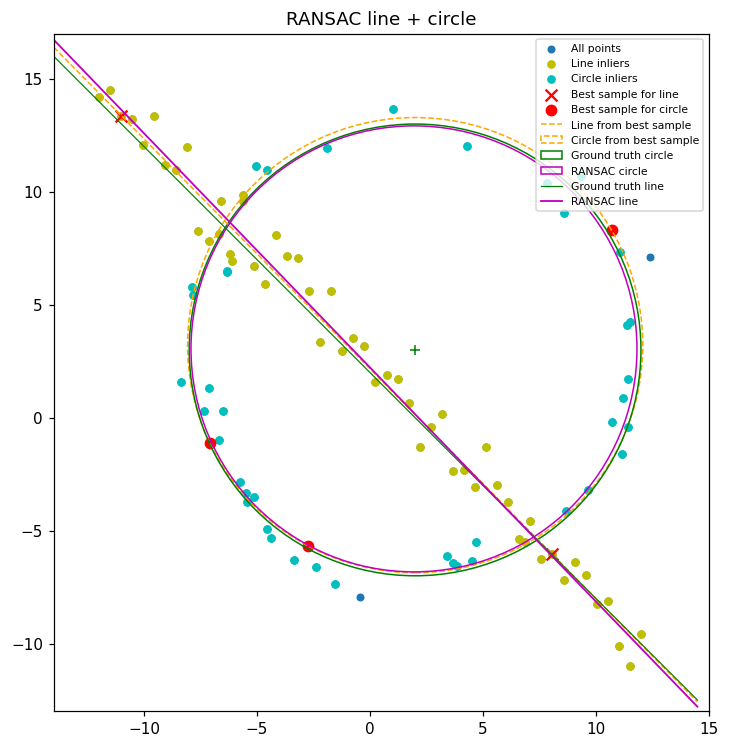

In [7]:
def plot_result(X, res_line, res_circ, remnant_idx, title="RANSAC line + circle"):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.scatter(*X.T, s=18, c="tab:blue", label="All points")
    ax.scatter(*X[res_line["inliers"]].T, s=22, c="y", label="Line inliers")
    circ_in_global = remnant_idx[res_circ["inliers"]]
    ax.scatter(*X[circ_in_global].T, s=22, c="c", label="Circle inliers")

    ls = X[res_line["sample"]]
    ax.scatter(*ls.T, marker="x", c="r", s=60, label="Best sample for line")
    cs = X[remnant_idx[res_circ["sample"]]]
    ax.scatter(*cs.T, c="r", s=45, label="Best sample for circle")

    xs = np.array([-14, 14.5])
    def draw_line(mdl, **kw):
        a, b, d = mdl
        if abs(b) > 1e-9: ax.plot(xs, (d - a * xs) / b, **kw)
        else: ax.axvline(d / a, **kw)
    draw_line(res_line["sample_model"], color="orange", ls="--", lw=1, label="Line from best sample")
    ax.add_patch(plt.Circle(res_circ["sample_model"][:2], res_circ["sample_model"][2],
                            fill=False, color="orange", ls="--", lw=1, label="Circle from best sample"))
    ax.add_patch(plt.Circle((x0_gt, y0_gt), r, fill=False, color="g", label="Ground truth circle"))
    ax.add_patch(plt.Circle(res_circ["model"][:2], res_circ["model"][2], fill=False, color="m", label="RANSAC circle"))
    ax.plot(xs, m_gt * xs + b_gt, color="g", lw=0.8, label="Ground truth line")
    draw_line(res_line["model"], color="m", lw=1.2, label="RANSAC line")
    ax.plot(x0_gt, y0_gt, "g+")
    ax.set_xlim(-14, 15); ax.set_ylim(-13, 17); ax.set_aspect("equal")
    ax.legend(fontsize=7, loc="upper right"); ax.set_title(title); plt.show()

plot_result(X, res_line, res_circ, remnant_idx)

### Q2(a–c) – Discussion

With 200 trials and a threshold of 1.5, I obtained the line $0.7195x+0.6945y=1.5467$. This is close to the ground-truth line $0.7071x+0.7071y=1.4142$, and the fitted normal has unit length. The final consensus contained 54 points: all 50 generated line points and four circle points near the intersections. The mean perpendicular inlier error was 0.573.

After removing these points, 46 points remained for circle fitting. With 500 trials and a radial threshold of 1.25, I obtained centre (1.951, 3.046) and radius 9.873. The centre error was 0.067, the absolute radius error was 0.127, and the mean radial inlier error was 0.442. The final circle consensus contained 44 points, all generated from the circle.

The combined plot shows that both refined models are close to the ground truth. I used green for the true models, orange dashed curves for the sample models, and magenta for the refined fits. Refinement uses the full winning consensus rather than only the sampled points. I recalculated the inliers after refinement so that the printed counts and plotted points correspond to the final models. A lower fitting error does not necessarily mean that every parameter is closer to its true value.

One limitation of removing the line first is that the four circle points included in the line consensus are lost before circle fitting. The threshold therefore affects both stages: increasing it can admit more points from the other structure, while decreasing it can reject noisy points from the intended structure. I used the minimum consensus of 35 to reject poorly supported models.


## Q2(d) – Fitting the circle first

I also fitted a circle directly to all 100 points before removing the line. I used the same threshold, 500 trials and a fresh random seed of 2 for both circle experiments. This allowed me to compare the results with and without the line points present.


circle-first: inliers=57, centre=(1.95, 3.05), r=9.92   (ground truth (2, 3), 10)
line-first  : inliers=44, centre=(1.95, 3.05), r=9.87


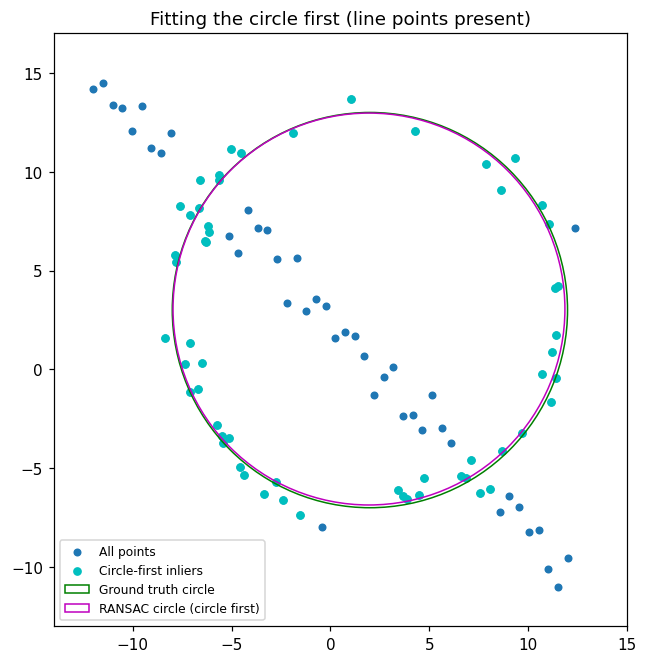

Circle-first membership: 48 generated circle points, 9 generated line points
Circle-first centre error: 0.072; radius error: 0.085


In [8]:
res_circ_first = ransac_circle(X, CIRC_THRESH, CIRC_MIN, CIRC_ITERS)
cx2, cy2, cr2 = res_circ_first["model"]
print(f"circle-first: inliers={res_circ_first['count']}, centre=({cx2:.2f}, {cy2:.2f}), r={cr2:.2f}   (ground truth (2, 3), 10)")
print(f"line-first  : inliers={res_circ['count']}, centre=({cx:.2f}, {cy:.2f}), r={cr:.2f}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(*X.T, s=18, label="All points")
ax.scatter(*X[res_circ_first["inliers"]].T, s=22, c="c", label="Circle-first inliers")
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, fill=False, color="g", label="Ground truth circle"))
ax.add_patch(plt.Circle((cx2, cy2), cr2, fill=False, color="m", label="RANSAC circle (circle first)"))
ax.set_xlim(-14, 15); ax.set_ylim(-13, 17); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title("Fitting the circle first (line points present)"); plt.show()
print(f"Circle-first membership: {res_circ_first['inliers'][:half_n].sum()} generated circle points, "
      f"{res_circ_first['inliers'][half_n:].sum()} generated line points")
print(f"Circle-first centre error: {np.hypot(cx2-x0_gt, cy2-y0_gt):.3f}; radius error: {abs(cr2-r):.3f}")

### Q2(d) – Discussion

When I fitted the circle first, I obtained centre (1.95, 3.05) and radius 9.92. The centre error was 0.072 and the absolute radius error was 0.085. The model had 57 inliers, but these included nine line points along with 48 circle points. The larger consensus therefore contained more points from the wrong structure.

For this data set, fitting the circle first still recovered a circle close to the ground truth. Its radius was slightly closer to 10 than the radius from the line-first fit, while its centre error was slightly larger. The line-first method gave a cleaner circle consensus of 44 circle points and no line points, but removed four genuine circle points during the line-fitting stage.

Before removing the line, the probability of sampling three genuine circle points without replacement was $(50/100)(49/99)(48/98)\approx0.121$. After line removal, all 46 remaining points came from the circle, although noise still placed some outside the threshold. This makes a circle-only sample easier to obtain, but does not guarantee an accurate circle from every sample.

The line points act as structured outliers. A large-radius circle can follow part of a line closely and receive votes from those points. That failure did not occur in this run, so I cannot conclude that fitting the circle first always fails or needs more iterations. Both experiments used the same iteration count; comparing reliability would require repeating the experiment with several data seeds.
